In [86]:
import os
import glob
import numpy as np
import tensorflow as tf



In [95]:
# ====== CONFIGURATION ======
# Same path as your previous project
SPLIT_ROOT = r"C:\Users\chama\OneDrive\Desktop\research_try\split_subject"

BATCH_SIZE = 4
SEED = 42

# Reproducibility
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Libraries imported and configuration set.")

Libraries imported and configuration set.


In [96]:
def get_paired_files(split):
    """
    Returns:
      X_left: list of file paths for Left Hippocampus
      X_right: list of file paths for Right Hippocampus
      y: numpy array of labels (AD=1, CN=0)
    """
    # Define paths for Left and Right
    left_base = os.path.join(SPLIT_ROOT, "left", split)
    right_base = os.path.join(SPLIT_ROOT, "right", split)

    # 1. Get AD files
    # We use sorted() to ensure the order is identical based on Subject ID
    ad_left = sorted(glob.glob(os.path.join(left_base, "AD", "*.npy")))
    ad_right = sorted(glob.glob(os.path.join(right_base, "AD", "*.npy")))

    # 2. Get CN files
    cn_left = sorted(glob.glob(os.path.join(left_base, "CN", "*.npy")))
    cn_right = sorted(glob.glob(os.path.join(right_base, "CN", "*.npy")))

    # SANITY CHECK: The number of files must be exactly the same
    if len(ad_left) != len(ad_right):
        raise ValueError(f"Mismatch in AD files! Left: {len(ad_left)}, Right: {len(ad_right)}")
    if len(cn_left) != len(cn_right):
        raise ValueError(f"Mismatch in CN files! Left: {len(cn_left)}, Right: {len(cn_right)}")

    # Combine AD and CN
    X_left = ad_left + cn_left
    X_right = ad_right + cn_right
    
    # Create labels (1 for AD, 0 for CN)
    y = np.array([1] * len(ad_left) + [0] * len(cn_left), dtype=np.int32)

    return X_left, X_right, y

# --- Load the File Lists ---
X_train_L, X_train_R, y_train = get_paired_files("train")
X_val_L,   X_val_R,   y_val   = get_paired_files("val")
X_test_L,  X_test_R,  y_test  = get_paired_files("test")

# Shuffle Training Data (keeping pairs together)
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(X_train_L))

X_train_L = [X_train_L[i] for i in perm]
X_train_R = [X_train_R[i] for i in perm]
y_train = y_train[perm]

print(f"Train Pairs: {len(X_train_L)} (AD: {sum(y_train)}, CN: {len(y_train)-sum(y_train)})")
print(f"Val Pairs:   {len(X_val_L)}")
print(f"Test Pairs:  {len(X_test_L)}")

Train Pairs: 48 (AD: 20, CN: 28)
Val Pairs:   10
Test Pairs:  12


In [97]:
def load_paired_npy(path_l, path_r, label):
    """
    Loads both Left and Right .npy files.
    Returns: ((left_img, right_img), label)
    """
    def _read_numpy_pair(pl, pr):
        # Load Left
        arr_l = np.load(pl.decode("utf-8"))
        arr_l = np.transpose(arr_l, (1, 2, 3, 0)) # (64,64,64,1)
        
        # Load Right
        arr_r = np.load(pr.decode("utf-8"))
        arr_r = np.transpose(arr_r, (1, 2, 3, 0)) # (64,64,64,1)
        
        return arr_l.astype(np.float32), arr_r.astype(np.float32)

    # Wrap the numpy function
    x_l, x_r = tf.numpy_function(_read_numpy_pair, [path_l, path_r], [tf.float32, tf.float32])
    
    # Set Shapes (Critical for Keras)
    x_l.set_shape((64, 64, 64, 1))
    x_r.set_shape((64, 64, 64, 1))

    y = tf.cast(label, tf.float32)
    
    # Return structure: ((input1, input2), target)
    return (x_l, x_r), y

def make_paired_dataset(X_l, X_r, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((X_l, X_r, y))
    
    if training:
        ds = ds.shuffle(buffer_size=len(X_l), seed=SEED, reshuffle_each_iteration=True)
        
    ds = ds.map(load_paired_npy, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

# Create the datasets
train_ds = make_paired_dataset(X_train_L, X_train_R, y_train, training=True)
val_ds   = make_paired_dataset(X_val_L,   X_val_R,   y_val,   training=False)
test_ds  = make_paired_dataset(X_test_L,  X_test_R,  y_test,  training=False)

# Check one batch
for (xb_l, xb_r), yb in train_ds.take(1):
    print("Left Batch:", xb_l.shape)
    print("Right Batch:", xb_r.shape)
    print("Labels:", yb.numpy())

Left Batch: (4, 64, 64, 64, 1)
Right Batch: (4, 64, 64, 64, 1)
Labels: [1. 0. 0. 1.]


In [98]:
@tf.function
def random_shift_3d_batch(x, max_shift=2):
    # This function is the same as before, just reused here
    B = tf.shape(x)[0]
    pad = max_shift
    sx = tf.random.uniform([B], -max_shift, max_shift + 1, dtype=tf.int32)
    sy = tf.random.uniform([B], -max_shift, max_shift + 1, dtype=tf.int32)
    sz = tf.random.uniform([B], -max_shift, max_shift + 1, dtype=tf.int32)
    x_pad = tf.pad(x, [[0, 0], [pad, pad], [pad, pad], [pad, pad], [0, 0]])

    def shift_one(args):
        xi, dx, dy, dz = args
        start_x = pad + dx
        start_y = pad + dy
        start_z = pad + dz
        return tf.slice(xi, [start_x, start_y, start_z, 0], [64, 64, 64, 1])

    return tf.map_fn(shift_one, (x_pad, sx, sy, sz), fn_output_signature=tf.float32)

@tf.function
def augment_pair_batch(inputs, y):
    """
    inputs: tuple (left_img, right_img)
    y: labels
    """
    x_l, x_r = inputs
    
    # --- Augment Left ---
    x_l = random_shift_3d_batch(x_l)
    x_l = x_l * tf.random.uniform([], 0.9, 1.1) # Scale
    x_l = x_l + tf.random.uniform([], -0.1, 0.1) # Shift
    x_l = x_l + tf.random.normal(tf.shape(x_l), 0.0, 0.03) # Noise

    # --- Augment Right ---
    x_r = random_shift_3d_batch(x_r)
    x_r = x_r * tf.random.uniform([], 0.9, 1.1)
    x_r = x_r + tf.random.uniform([], -0.1, 0.1)
    x_r = x_r + tf.random.normal(tf.shape(x_r), 0.0, 0.03)

    return (x_l, x_r), y

# Apply augmentation to training set
train_ds_aug = train_ds.map(augment_pair_batch, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

print("Data Augmentation pipeline ready.")

Data Augmentation pipeline ready.


In [101]:
from tensorflow import keras
from tensorflow.keras import layers

def get_feature_extractor(name_prefix):
    """
    Creates the CNN branch (Block 1 to Dense Layer).
    It is identical to your previous model, but WITHOUT the final Sigmoid.
    """
    inputs = keras.Input(shape=(64, 64, 64, 1))

    # Block 1
    x = layers.Conv3D(16, 3, padding="same")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPool3D(2)(x)   # 64 -> 32

    # Block 2
    x = layers.Conv3D(32, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPool3D(2)(x)   # 32 -> 16

    x = layers.Conv3D(32, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPool3D(2)(x)

    # Block 3
    x = layers.Conv3D(32, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPool3D(2)(x)   # 16 -> 8

    x = layers.Conv3D(64, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPool3D(2)(x)   # 16 -> 8

    # Block 4 (deeper features)
    x = layers.Conv3D(64, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)


    # --- Global Pooling & Dense Vector ---
    x = layers.GlobalAveragePooling3D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dense(32, activation="relu")(x)
    # We include Dropout here as part of the branch
    outputs = layers.Dropout(0.2)(x)

    # Create the 'Branch' model
    # Note: We give it a unique name so we can distinguish Left/Right weights later
    model = keras.Model(inputs, outputs, name=f"{name_prefix}_branch")
    return model

def build_dual_stream_model():
    # 1. Define Inputs
    input_l = keras.Input(shape=(64, 64, 64, 1), name="left_input")
    input_r = keras.Input(shape=(64, 64, 64, 1), name="right_input")

    # 2. Create the two separate branches
    # We call the function twice to create two INDEPENDENT models with their own weights
    left_branch  = get_feature_extractor("left")
    right_branch = get_feature_extractor("right")

    # 3. Pass inputs through branches
    # vector_l shape: (Batch, 64)
    vector_l = left_branch(input_l)
    # vector_r shape: (Batch, 64)
    vector_r = right_branch(input_r)

    # 4. Concatenate (Fusion)
    # Combined shape: (Batch, 128)
    concat = layers.Concatenate()([vector_l, vector_r])

    # 5. Final Classification Head
    # This layer sees info from BOTH sides to make the decision
    output = layers.Dense(1, activation="sigmoid", name="final_output")(concat)

    # 6. Build the Full Functional Model
    model = keras.Model(inputs=[input_l, input_r], outputs=output, name="dual_hippocampus_net")
    return model

# Build and Summarize
model = build_dual_stream_model()
model.summary()

Model: "dual_hippocampus_net"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ left_input          │ (None, 64, 64,    │          0 │ -                 │
│ (InputLayer)        │ 64, 1)            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ right_input         │ (None, 64, 64,    │          0 │ -                 │
│ (InputLayer)        │ 64, 1)            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ left_branch         │ (None, 32)        │    242,880 │ left_input[0][0]  │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ right_branch        │ (None, 32)        │    242,880 │ right_input[0][0] │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_12      │ (None, 64)        │          0 │ left_branch[0][0… │
│ (Concatenate)       │                   │            │ right_branch[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ final_output        │ (None, 1)         │         65 │ concatenate_12[0… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 485,825 (1.85 MB)

 Trainable params: 484,865 (1.85 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
# --- Calculate Class Weights ---
# We use the y_train from Cell 2
n_ad = int((y_train == 1).sum())
n_cn = int((y_train == 0).sum())
total = n_ad + n_cn

print(f"Training stats: AD={n_ad}, CN={n_cn}, Total={total}")

class_weight = {
    0: total / (2.0 * n_cn),  # Weight for CN
    1: total / (2.0 * n_ad)   # Weight for AD
}

print("Class Weights:", class_weight)

# --- Define Callbacks ---
callbacks = [
    # Stop if validation AUC doesn't improve for 30 epochs
    keras.callbacks.EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=30,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        filepath="best_dual_model.keras",
        monitor="val_auc",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_auc",
        mode="max",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
]
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=5e-5),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="acc"),
        keras.metrics.AUC(name="auc")
    ]
)

print("Model compiled and ready to train.")

Training stats: AD=20, CN=28, Total=48
Class Weights: {0: 0.8571428571428571, 1: 1.2}
Model compiled and ready to train.


In [103]:
EPOCHS = 100  # We give it plenty of time; EarlyStopping will cut it short if needed

history = model.fit(
    train_ds_aug,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    class_weight=class_weight
)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 801ms/step - acc: 0.5639 - auc: 0.6903 - loss: 0.7092
Epoch 1: val_auc improved from None to 0.72917, saving model to best_dual_model.keras
12/12 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - acc: 0.5833 - auc: 0.6562 - loss: 0.6972 - val_acc: 0.6000 - val_auc: 0.7292 - val_loss: 0.6680 - learning_rate: 5.0000e-05
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 874ms/step - acc: 0.5540 - auc: 0.7300 - loss: 0.7030
Epoch 2: val_auc did not improve from 0.72917
12/12 ━━━━━━━━━━━━━━━━━━━━ 12s 933ms/step - acc: 0.6042 - auc: 0.7107 - loss: 0.6726 - val_acc: 0.6000 - val_auc: 0.6875 - val_loss: 0.6641 - learning_rate: 5.0000e-05
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 884ms/step - acc: 0.5750 - auc: 0.7768 - loss: 0.6717
Epoch 3: val_auc improved from 0.72917 to 0.77083, saving model to best_dual_model.keras
12/12 ━━━━━━━━━━━━━━━━━━━━ 12s 984ms/step - acc: 0.6042 - auc: 0.7330 - loss: 0.6670 - val_acc: 0.6000 - val_auc: 0.7708 - val_loss: 0.6613 - learning_rate: 5

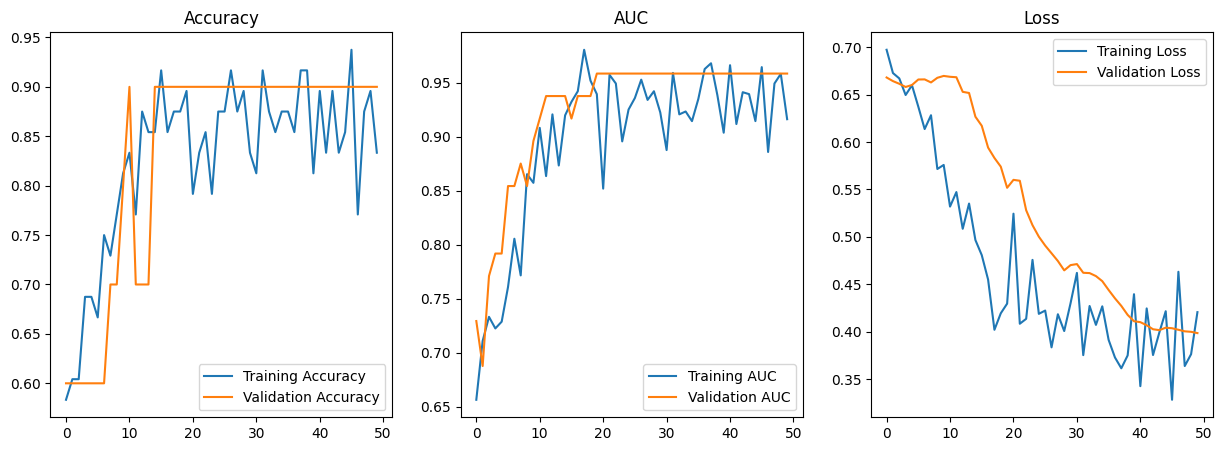

In [104]:
import matplotlib.pyplot as plt

def plot_history(history):
    acc = history.history['acc']
    val_acc = history.history['val_acc']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    auc = history.history['auc']
    val_auc = history.history['val_auc']
    
    epochs_range = range(len(acc))

    plt.figure(figsize=(15, 5))
    
    # Plot Accuracy
    plt.subplot(1, 3, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title('Accuracy')

    # Plot AUC
    plt.subplot(1, 3, 2)
    plt.plot(epochs_range, auc, label='Training AUC')
    plt.plot(epochs_range, val_auc, label='Validation AUC')
    plt.legend(loc='lower right')
    plt.title('AUC')

    # Plot Loss
    plt.subplot(1, 3, 3)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title('Loss')
    
    plt.show()

plot_history(history)

In [105]:
model.save("final_fused_model.keras")

In [106]:
print("Evaluating on Test Set...")
test_loss, test_acc, test_auc = model.evaluate(test_ds)

print(f"\nFinal Test Results:")
print(f"Accuracy: {test_acc:.4f}")
print(f"AUC:      {test_auc:.4f}")
print(f"Loss:     {test_loss:.4f}")

Evaluating on Test Set...
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step - acc: 0.8333 - auc: 0.9429 - loss: 0.5362  

Final Test Results:
Accuracy: 0.8333
AUC:      0.9429
Loss:     0.5362


3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 203ms/step

       FINAL MODEL PERFORMANCE
Accuracy:  0.8333
Precision: 0.7143
Recall:    1.0000
F1 Score:  0.8333
----------------------------------------

Detailed Report:
                precision    recall  f1-score   support

   CN (Normal)       1.00      0.71      0.83         7
AD (Alzheimer)       0.71      1.00      0.83         5

      accuracy                           0.83        12
     macro avg       0.86      0.86      0.83        12
  weighted avg       0.88      0.83      0.83        12



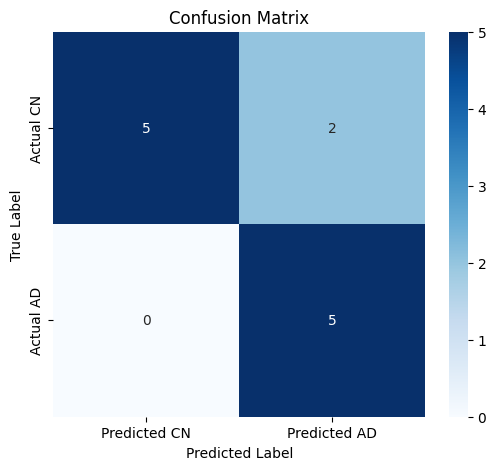

Correctly Identified AD: 5
Correctly Identified CN: 5
False Alarms (CN called AD): 2
Missed Diagnosis (AD called CN): 0


In [108]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score, f1_score
from tensorflow import keras
# 2. Get Predictions
# verbose=1 shows a progress bar
y_pred_prob = model.predict(test_ds, verbose=1)

# 3. Convert Probabilities to Class Labels (Threshold = 0.5)
y_pred_class = (y_pred_prob >= 0.5).astype(int).flatten()

# 4. Get True Labels
# We use the y_test numpy array we created in the "Data Loading" step.
# If y_test is not available, we can extract it from the dataset:
y_true = np.concatenate([y for x, y in test_ds], axis=0)

# 5. Calculate Metrics
precision = precision_score(y_true, y_pred_class)
recall = recall_score(y_true, y_pred_class)
f1 = f1_score(y_true, y_pred_class)
accuracy = np.mean(y_true == y_pred_class)

# 6. Print Final Report
print("\n" + "="*40)
print("       FINAL MODEL PERFORMANCE")
print("="*40)
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print("-" * 40)

# 7. Detailed Classification Report (Text Version)
print("\nDetailed Report:")
print(classification_report(y_true, y_pred_class, target_names=['CN (Normal)', 'AD (Alzheimer)']))

# 8. Plot Confusion Matrix
cm = confusion_matrix(y_true, y_pred_class)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Predicted CN', 'Predicted AD'], 
            yticklabels=['Actual CN', 'Actual AD'])
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

# 9. Interpretation Helper
tn, fp, fn, tp = cm.ravel()
print(f"Correctly Identified AD: {tp}")
print(f"Correctly Identified CN: {tn}")
print(f"False Alarms (CN called AD): {fp}")
print(f"Missed Diagnosis (AD called CN): {fn}")

In [2]:
import numpy as np
import tensorflow as tf
from tensorflow import keras

FUSION_MODEL_PATH = "final_fused_model.keras"   # your saved fusion model
LEFT_NPY  = r"C:\Users\chama\OneDrive\Desktop\research_try\demo_input\subject_left.npy"
RIGHT_NPY = r"C:\Users\chama\OneDrive\Desktop\research_try\demo_input\subject_right.npy"

def load_patch(path):
    x = np.load(path)
    # If saved as (1,64,64,64) -> convert to (64,64,64,1)
    if x.shape == (1,64,64,64):
        x = np.transpose(x, (1,2,3,0))
    # If saved as (64,64,64) -> add channel
    if x.shape == (64,64,64):
        x = x[..., None]
    # Add batch dim -> (1,64,64,64,1)
    x = x.astype(np.float32)[None, ...]
    return x

fusion_model = keras.models.load_model(FUSION_MODEL_PATH)

xL = load_patch(LEFT_NPY)
xR = load_patch(RIGHT_NPY)

prob_ad = float(fusion_model.predict([xL, xR], verbose=0).ravel()[0])
pred = "AD" if prob_ad >= 0.5 else "CN"

print("Prediction:", pred)
print("AD probability:", round(prob_ad, 4))


Prediction: AD
AD probability: 0.6438


# Apply cross validation


In [109]:
import numpy as np
from sklearn.model_selection import StratifiedKFold

# 1. Merge Train and Val lists (Keep Test separate!)
X_all_L = X_train_L + X_val_L
X_all_R = X_train_R + X_val_R
y_all   = np.concatenate([y_train, y_val], axis=0)

# Convert lists to numpy arrays for easier indexing during the loop
X_all_L = np.array(X_all_L)
X_all_R = np.array(X_all_R)

print(f"Total Combined Data for K-Fold: {len(y_all)} subjects")

Total Combined Data for K-Fold: 58 subjects


In [110]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from tensorflow import keras
import tensorflow as tf

# --- CONFIGURATION ---
K_FOLDS = 10
EPOCHS_PER_FOLD = 60
BATCH_SIZE = 4

skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)

# STORE HISTORIES HERE
all_histories = [] 
fold_accuracies = []
fold_aucs = []

print(f"Starting {K_FOLDS}-Fold Cross-Validation...\n")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_all_L, y_all)):
    print(f"=== FOLD {fold+1} / {K_FOLDS} ===")
    
    tf.keras.backend.clear_session() # Clear memory
    
    # 1. Prepare Data
    X_tr_L, X_val_L_fold = X_all_L[train_idx], X_all_L[val_idx]
    X_tr_R, X_val_R_fold = X_all_R[train_idx], X_all_R[val_idx]
    y_tr,   y_val_fold   = y_all[train_idx],   y_all[val_idx]
    
    train_ds_fold = make_paired_dataset(X_tr_L, X_tr_R, y_tr, training=True)
    val_ds_fold   = make_paired_dataset(X_val_L_fold, X_val_R_fold, y_val_fold, training=False)
    train_ds_fold = train_ds_fold.map(augment_pair_batch, num_parallel_calls=tf.data.AUTOTUNE)

    # 2. Class Weights
    n_ad_f = int((y_tr == 1).sum())
    n_cn_f = int((y_tr == 0).sum())
    total_f = n_ad_f + n_cn_f
    class_weight_fold = {0: total_f/(2*n_cn_f), 1: total_f/(2*n_ad_f)}

    # 3. Build & Train
    model = build_dual_stream_model()
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-5),
        loss="binary_crossentropy",
        metrics=[keras.metrics.BinaryAccuracy(name="acc"), keras.metrics.AUC(name="auc")]
    )
    
    # Note: We use a simple EarlyStopping to keep lengths similar, or just run full epochs
    callback = keras.callbacks.EarlyStopping(monitor='val_auc', patience=15, restore_best_weights=True)

    history = model.fit(
        train_ds_fold,
        validation_data=val_ds_fold,
        epochs=EPOCHS_PER_FOLD,
        callbacks=[callback],
        class_weight=class_weight_fold,
        verbose=1
    )
    
    # --- SAVE HISTORY ---
    all_histories.append(history.history)
    
    # Evaluate
    scores = model.evaluate(val_ds_fold, verbose=0)
    fold_accuracies.append(scores[1])
    fold_aucs.append(scores[2])
    print(f"Fold {fold+1} Acc: {scores[1]:.4f}")
# --- Final Report ---
print("\n" + "="*30)
print("CROSS-VALIDATION RESULTS")
print("="*30)
print(f"Accuracies: {fold_accuracies}")
print(f"AUCs:       {fold_aucs}")
print(f"Mean Accuracy: {np.mean(fold_accuracies):.4f} (+/- {np.std(fold_accuracies):.4f})")
print(f"Mean AUC:      {np.mean(fold_aucs):.4f} (+/- {np.std(fold_aucs):.4f})")
print("Done! Histories saved.")

Starting 10-Fold Cross-Validation...

=== FOLD 1 / 10 ===
Epoch 1/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 162s 2s/step - acc: 0.4231 - auc: 0.5068 - loss: 0.7109 - val_acc: 0.3333 - val_auc: 0.5000 - val_loss: 0.6991
Epoch 2/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - acc: 0.4423 - auc: 0.3856 - loss: 0.7293 - val_acc: 0.3333 - val_auc: 0.5000 - val_loss: 0.7056
Epoch 3/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - acc: 0.4423 - auc: 0.5152 - loss: 0.7116 - val_acc: 0.3333 - val_auc: 0.2500 - val_loss: 0.7142
Epoch 4/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - acc: 0.4038 - auc: 0.5780 - loss: 0.6993 - val_acc: 0.3333 - val_auc: 0.3750 - val_loss: 0.7224
Epoch 5/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - acc: 0.4615 - auc: 0.5947 - loss: 0.6903 - val_acc: 0.3333 - val_auc: 0.5000 - val_loss: 0.7293
Epoch 6/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - acc: 0.4231 - auc: 0.6174 - loss: 0.6891 - val_acc: 0.3333 - val_auc: 0.3750 - val_loss: 0.7345
Epoch 7/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - a

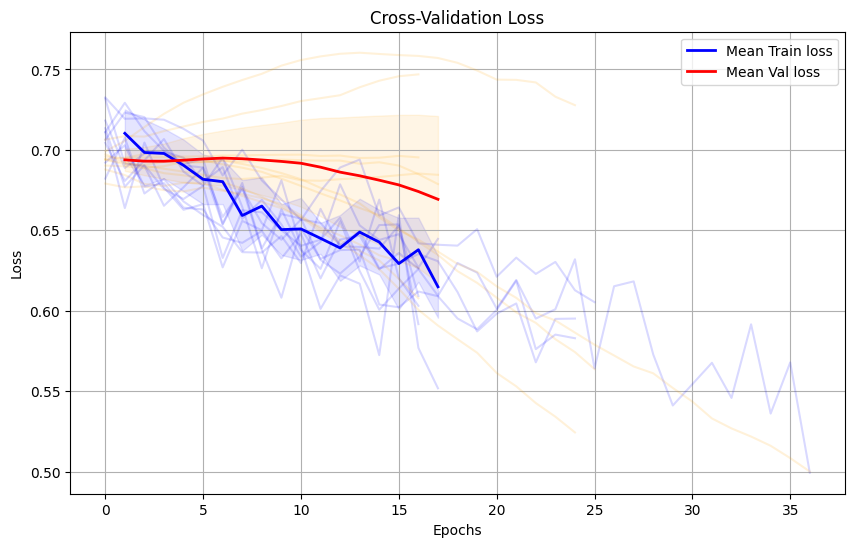

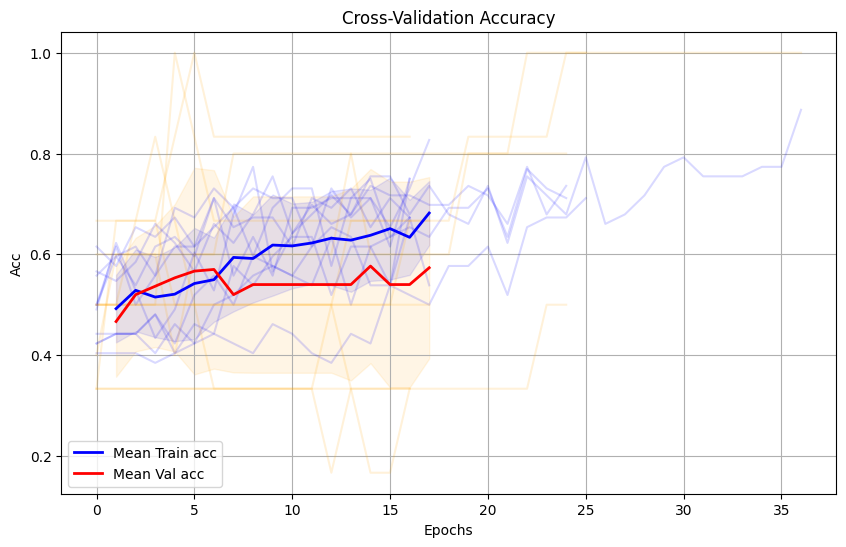

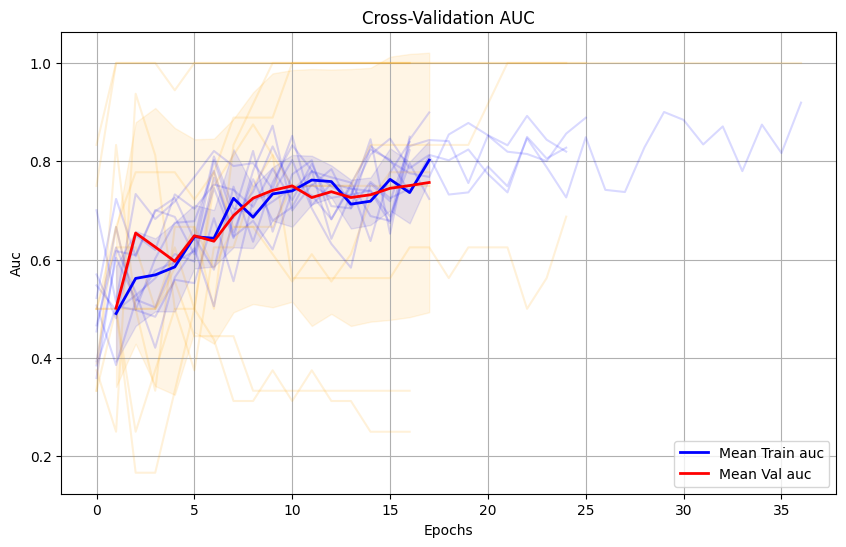

In [111]:
def plot_cross_val_metric(histories, metric, title):
    plt.figure(figsize=(10, 6))
    
    # 1. Determine minimum number of epochs across all folds
    min_epochs = min([len(h[metric]) for h in histories])
    
    # 2. Collect data up to min_epochs
    # shape: (n_folds, min_epochs)
    train_data = np.array([h[metric][:min_epochs] for h in histories])
    val_data   = np.array([h[f"val_{metric}"][:min_epochs] for h in histories])
    
    # 3. Calculate Mean and Standard Deviation
    mean_train = np.mean(train_data, axis=0)
    std_train  = np.std(train_data, axis=0)
    
    mean_val   = np.mean(val_data, axis=0)
    std_val    = np.std(val_data, axis=0)
    
    epochs = range(1, min_epochs + 1)
    
    # 4. Plot Individual Folds (Faint lines)
    for i in range(len(histories)):
        plt.plot(histories[i][metric], color='blue', alpha=0.15)
        plt.plot(histories[i][f"val_{metric}"], color='orange', alpha=0.15)

    # 5. Plot Mean Curves (Bold)
    plt.plot(epochs, mean_train, 'b-', label=f'Mean Train {metric}', linewidth=2)
    plt.plot(epochs, mean_val,   'r-', label=f'Mean Val {metric}', linewidth=2)
    
    # 6. Fill area between Mean +/- Std Dev (Shading)
    plt.fill_between(epochs, mean_train - std_train, mean_train + std_train, color='blue', alpha=0.1)
    plt.fill_between(epochs, mean_val - std_val,     mean_val + std_val,     color='orange', alpha=0.1)

    plt.title(f'Cross-Validation {title}')
    plt.xlabel('Epochs')
    plt.ylabel(metric.capitalize())
    plt.legend()
    plt.grid(True)
    plt.show()

# --- EXECUTE PLOTS ---
plot_cross_val_metric(all_histories, 'loss', 'Loss')
plot_cross_val_metric(all_histories, 'acc',  'Accuracy')
plot_cross_val_metric(all_histories, 'auc',  'AUC')